# Diffusion Data Setup: Binary Leaf Silhouette Masks

Generates **full-leaf binary silhouette masks** for all 263 GLS diseased images.
These masks serve as the conditioning signal for the mask-conditioned DDPM in
`diffusion_train_linux.ipynb`.

## What this notebook does
1. Loads each image from `data/diseased/gls/`
2. Extracts the leaf silhouette (entire leaf body, not just lesion spots) using
   HSV brightness thresholding + morphological cleanup + largest connected component
   — the same strategy used in `src/lesion_mask/gls_mask_creator.ipynb`
3. Saves binary masks to `data/masks/leaf/gls/leaf_mask_001.png` … `leaf_mask_263.png`
4. Provides an interactive viewer and a quality report

## Output
- **Domain**: `data/masks/leaf/gls/`  (currently empty)
- **Format**: 8-bit PNG, white = leaf (255), black = background (0)
- **Resolution**: same as input image (original resolution)

**Target**: A100 GPU on Lambda Labs cloud (CPU-only task — no GPU needed)

In [1]:
# 1. Imports
import os
import sys
import cv2
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm.notebook import tqdm
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt

# ipywidgets for interactive verification (optional — falls back gracefully if missing)
try:
    import ipywidgets as widgets
    from IPython.display import display
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print('ipywidgets not available — skipping interactive viewer.')

In [2]:
# 2. Configuration

# ----- Resolve repo root (notebook is at src/gan/diffusion_data_setup.ipynb) -----
repo_root = Path.cwd().resolve()
if repo_root.name == 'gan':
    repo_root = repo_root.parents[1]
elif repo_root.name == 'src':
    repo_root = repo_root.parent
print(f'Repo root: {repo_root}')

# ----- Paths -----
IMAGE_DIR  = str(repo_root / 'data' / 'diseased' / 'gls')
OUTPUT_DIR = str(repo_root / 'data' / 'masks' / 'leaf' / 'gls')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----- Morphological parameters (matched to gls_mask_creator.ipynb) -----
BRIGHTNESS_THRESHOLD = 20    # HSV V-channel: pixels with V <= this are background
MORPH_KERNEL_SIZE    = 7     # elliptical structuring element size
MORPH_CLOSE_ITERS    = 3     # close iterations (fill holes in leaf)
MORPH_OPEN_ITERS     = 1     # open iterations  (remove small noise)

image_files = sorted(f for f in os.listdir(IMAGE_DIR)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg')))
print(f'Found {len(image_files)} images in {IMAGE_DIR}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Morphology params: kernel={MORPH_KERNEL_SIZE}x{MORPH_KERNEL_SIZE}, '
      f'close_iters={MORPH_CLOSE_ITERS}, open_iters={MORPH_OPEN_ITERS}')

Repo root: C:\Users\henry\Desktop\isef2026
Found 263 images in C:\Users\henry\Desktop\isef2026\data\diseased\gls
Output directory: C:\Users\henry\Desktop\isef2026\data\masks\leaf\gls
Morphology params: kernel=7x7, close_iters=3, open_iters=1


Sanity check on leaf001.png:
  Image shape: (500, 500, 3)
  Mask shape:  (500, 500), dtype=uint8
  Mask area:   147724 px  (59.1% of image)


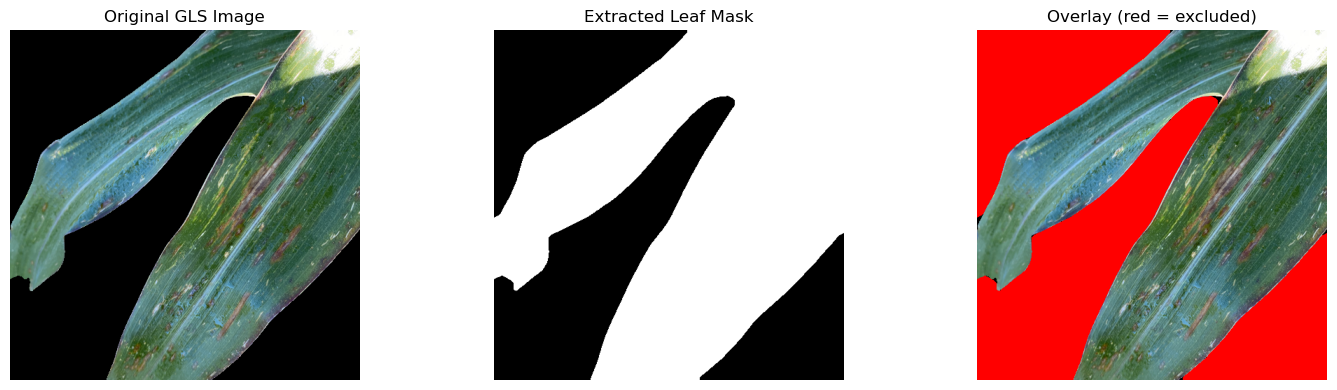

In [3]:
# 3. extract_leaf_mask() — adapted from gls_mask_creator.ipynb generate_masks()
# Extracts the full leaf silhouette (not just the diseased lesion spots).

def extract_leaf_mask(bgr_image):
    """Extract a binary full-leaf silhouette mask from a BGR image.

    Strategy (mirrors gls_mask_creator.ipynb):
      1. Convert to HSV
      2. Threshold V-channel: pixels with V > BRIGHTNESS_THRESHOLD are non-background
      3. Morphological close (fill internal holes) then open (remove noise)
      4. Keep only the largest connected component (= main leaf body)

    Args:
        bgr_image: np.ndarray [H, W, 3] in BGR format (as returned by cv2.imread)

    Returns:
        np.ndarray [H, W] uint8 — 255 = leaf, 0 = background
    """
    hsv = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2HSV)

    # Non-dark pixels = leaf (GLS images are typically photographed on dark backgrounds)
    leaf_mask = (hsv[:, :, 2] > BRIGHTNESS_THRESHOLD).astype(np.uint8) * 255

    # Morphological close: fill holes inside the leaf (e.g. dark lesion centres)
    kernel    = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                          (MORPH_KERNEL_SIZE, MORPH_KERNEL_SIZE))
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, kernel,
                                  iterations=MORPH_CLOSE_ITERS)
    # Morphological open: remove small isolated noise regions
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_OPEN, kernel,
                                  iterations=MORPH_OPEN_ITERS)

    # Keep only the largest connected component (the main leaf body)
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        leaf_mask, connectivity=8)
    if n_labels <= 1:
        # Nothing found — fall back to the thresholded mask
        return leaf_mask

    areas         = stats[1:, cv2.CC_STAT_AREA]   # exclude label 0 (background)
    largest_label = int(np.argmax(areas)) + 1
    return (labels == largest_label).astype(np.uint8) * 255


# Quick sanity check on the first image
test_img  = cv2.imread(os.path.join(IMAGE_DIR, image_files[0]))
test_mask = extract_leaf_mask(test_img)
print(f'Sanity check on {image_files[0]}:')
print(f'  Image shape: {test_img.shape}')
print(f'  Mask shape:  {test_mask.shape}, dtype={test_mask.dtype}')
print(f'  Mask area:   {test_mask.sum() // 255} px  '
      f'({100 * test_mask.mean() / 255:.1f}% of image)')

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
axs[0].set_title('Original GLS Image'); axs[0].axis('off')
axs[1].imshow(test_mask, cmap='gray')
axs[1].set_title('Extracted Leaf Mask'); axs[1].axis('off')
overlay = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB).copy()
overlay[test_mask == 0] = [255, 0, 0]   # red = background
axs[2].imshow(overlay)
axs[2].set_title('Overlay (red = excluded)'); axs[2].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# 4. Optional: GAN-A style geometric augmentation helper (image + mask synced)

# Mirrors the geometric policy used in ganA_data_setup.ipynb:
 # - random horizontal flip
 # - random vertical flip
 # - random 90-degree rotation
 # - random crop (80%-100%) and resize back

import random
from PIL import Image

def augment_image_mask_geometric(img_rgb, mask_u8, seed=None, crop_range=(0.8, 1.0)):
    """Apply identical geometric transforms to RGB image and binary mask.

    Args:
        img_rgb: np.ndarray [H, W, 3], uint8 RGB image
        mask_u8: np.ndarray [H, W], uint8 mask with values {0, 255}
        seed: optional int for reproducible augmentation
        crop_range: (min_scale, max_scale) for random crop area fraction

    Returns:
        aug_img: np.ndarray [H, W, 3], uint8 RGB
        aug_mask: np.ndarray [H, W], uint8 in {0, 255}
    """
    rng = random.Random(seed)

    img_pil = Image.fromarray(img_rgb).convert('RGB')
    msk_pil = Image.fromarray(mask_u8).convert('L')
    w, h = img_pil.size

    # Horizontal flip
    if rng.random() > 0.5:
        img_pil = img_pil.transpose(Image.FLIP_LEFT_RIGHT)
        msk_pil = msk_pil.transpose(Image.FLIP_LEFT_RIGHT)

    # Vertical flip
    if rng.random() > 0.5:
        img_pil = img_pil.transpose(Image.FLIP_TOP_BOTTOM)
        msk_pil = msk_pil.transpose(Image.FLIP_TOP_BOTTOM)

    # Rotation by multiples of 90 degrees
    angle = rng.choice([0, 90, 180, 270])
    if angle != 0:
        img_pil = img_pil.rotate(angle, expand=False)
        msk_pil = msk_pil.rotate(angle, expand=False)

    # Random crop (80%-100%) and resize back to original size
    crop_scale = rng.uniform(crop_range[0], crop_range[1])
    crop_w = int(w * crop_scale)
    crop_h = int(h * crop_scale)
    left = rng.randint(0, w - crop_w)
    top = rng.randint(0, h - crop_h)

    img_pil = img_pil.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.BILINEAR)
    msk_pil = msk_pil.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.NEAREST)

    aug_img = np.array(img_pil, dtype=np.uint8)
    aug_mask = np.array(msk_pil, dtype=np.uint8)
    aug_mask = (aug_mask > 127).astype(np.uint8) * 255
    return aug_img, aug_mask

print('Defined augment_image_mask_geometric(img_rgb, mask_u8, seed, crop_range).')
print('Use this for synchronized geometric augmentation consistent with GAN-A data setup.')

In [ ]:
# 4. Build augmented image-mask pairs

NUM_AUGMENTATIONS_PER_IMAGE = 3  # number of augmented copies per source image
PAIR_OUTPUT_ROOT = str(repo_root / 'data' / 'diseased' / 'gls_paired_augmented')
PAIR_IMAGE_DIR = os.path.join(PAIR_OUTPUT_ROOT, 'image')
PAIR_MASK_DIR = os.path.join(PAIR_OUTPUT_ROOT, 'mask')
os.makedirs(PAIR_IMAGE_DIR, exist_ok=True)
os.makedirs(PAIR_MASK_DIR, exist_ok=True)

if 'augment_image_mask_geometric' not in globals():
    raise RuntimeError('augment_image_mask_geometric is not defined. Run the augmentation helper cell first.')

failed = []
areas = []
pair_count = 0

for idx, fname in enumerate(tqdm(image_files, desc='Saving augmented pairs')):
    bgr = cv2.imread(os.path.join(IMAGE_DIR, fname))
    if bgr is None:
        print(f'WARNING: could not read {fname} — skipping.')
        failed.append(fname)
        continue

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    mask = extract_leaf_mask(bgr)
    area_frac = mask.mean() / 255.0
    areas.append((fname, area_frac, mask.shape))

    if area_frac == 0:
        print(f'WARNING: empty mask for {fname} — saving zeros.')
        failed.append(fname)

    base = os.path.splitext(fname)[0]

    # Save original pair
    orig_name = f'{base}_orig.png'
    cv2.imwrite(os.path.join(PAIR_IMAGE_DIR, orig_name), bgr)
    cv2.imwrite(os.path.join(PAIR_MASK_DIR, orig_name), mask)
    pair_count += 1

    # Save augmented copies with synchronized geometric transforms
    for aug_i in range(NUM_AUGMENTATIONS_PER_IMAGE):
        seed = 42 + idx * 100 + aug_i
        aug_rgb, aug_mask = augment_image_mask_geometric(rgb, mask, seed=seed, crop_range=(0.8, 1.0))
        aug_bgr = cv2.cvtColor(aug_rgb, cv2.COLOR_RGB2BGR)

        aug_name = f'{base}_aug{aug_i}.png'
        cv2.imwrite(os.path.join(PAIR_IMAGE_DIR, aug_name), aug_bgr)
        cv2.imwrite(os.path.join(PAIR_MASK_DIR, aug_name), aug_mask)
        pair_count += 1

print(f'\nAugmented paired dataset saved to: {PAIR_OUTPUT_ROOT}')
print(f'Total saved pairs (orig + aug): {pair_count}')
print(f'Failed / empty: {len(failed)} — {failed if failed else "none"}')

Extracting leaf masks:   0%|          | 0/263 [00:00<?, ?it/s]


Done. 263 masks saved to C:\Users\henry\Desktop\isef2026\data\masks\leaf\gls
Failed / empty: 0 — none


In [5]:
# 5. Interactive verification widget
# Shows original image | leaf mask | overlay for each image index.
# Requires ipywidgets (installed in the conda environment).

mask_files = sorted(f for f in os.listdir(OUTPUT_DIR)
                    if f.lower().endswith('.png'))

if HAS_WIDGETS and len(mask_files) > 0:
    def show_pair(idx):
        img_path  = os.path.join(IMAGE_DIR,  image_files[idx])
        mask_path = os.path.join(OUTPUT_DIR, mask_files[idx])
        bgr  = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        overlay = rgb.copy()
        overlay[mask == 0] = [200, 50, 50]
        area = 100 * mask.mean() / 255
        fig, axs = plt.subplots(1, 3, figsize=(15, 4))
        axs[0].imshow(rgb);     axs[0].set_title(image_files[idx]); axs[0].axis('off')
        axs[1].imshow(mask, cmap='gray')
        axs[1].set_title(f'Leaf mask  ({area:.1f}% coverage)'); axs[1].axis('off')
        axs[2].imshow(overlay); axs[2].set_title('Overlay (red = bg)'); axs[2].axis('off')
        plt.tight_layout(); plt.show()

    slider = widgets.IntSlider(value=0, min=0, max=len(mask_files) - 1,
                               description='Index:', continuous_update=False)
    widgets.interact(show_pair, idx=slider)
else:
    # Fallback: show a static 3x3 grid of random samples
    import random
    sample_idx = random.sample(range(len(image_files)), min(9, len(image_files)))
    fig, axs = plt.subplots(3, 3, figsize=(15, 12))
    for ax, i in zip(axs.flat, sample_idx):
        mask_path = os.path.join(OUTPUT_DIR, mask_files[i])
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        ax.imshow(mask, cmap='gray')
        ax.set_title(mask_files[i], fontsize=8)
        ax.axis('off')
    plt.suptitle('Sample Leaf Masks (static preview)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=0, continuous_update=False, description='Index:', max=262), Output()), _…

LEAF MASK QUALITY REPORT
  Total masks generated:  263
  Empty masks (area=0):   0
  Very small (<5%):       0
  Normal (5%–80%):        258
  Very large (>80%):      5
  Mean coverage:          50.1%
  Std coverage:           14.3%
  Min coverage:           19.7%
  Max coverage:           92.7%


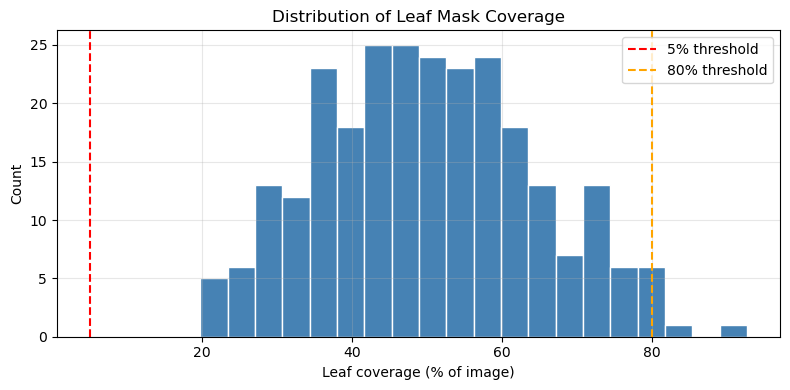

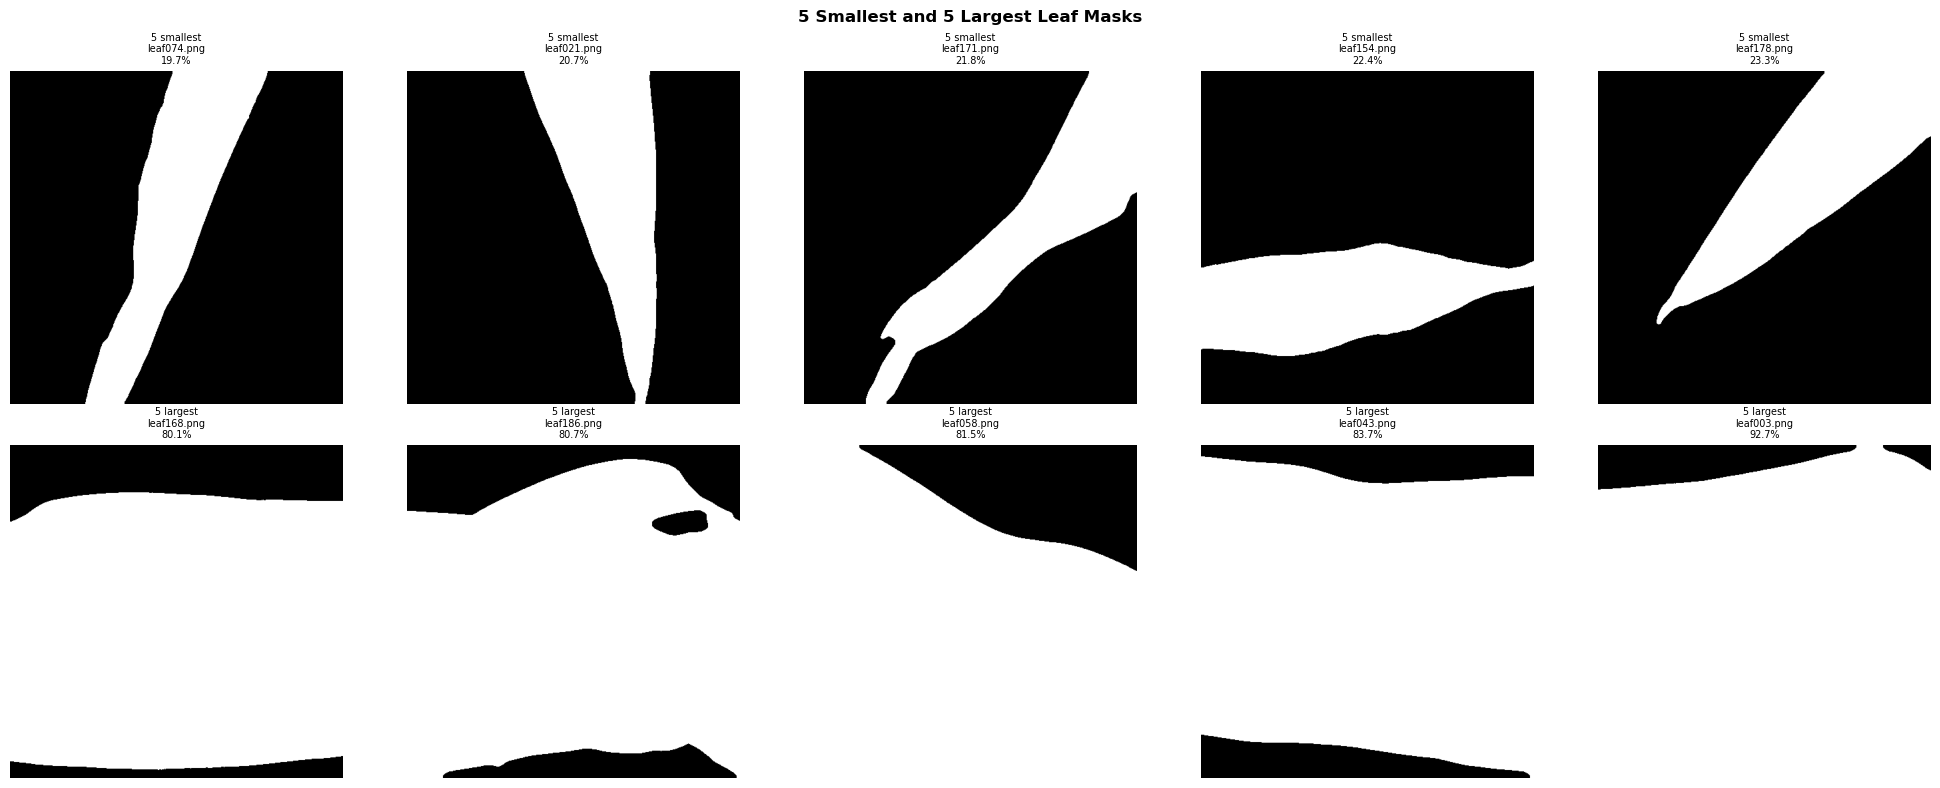


If any masks look incorrect, adjust BRIGHTNESS_THRESHOLD or MORPH_* parameters in cell 2
and re-run cells 2–4.


In [6]:
# 6. Quality report

area_fracs = [a for _, a, _ in areas]
area_fracs_np = np.array(area_fracs)

print('=' * 55)
print('LEAF MASK QUALITY REPORT')
print('=' * 55)
print(f'  Total masks generated:  {len(areas)}')
print(f'  Empty masks (area=0):   {sum(1 for a in area_fracs if a == 0)}')
print(f'  Very small (<5%):       {sum(1 for a in area_fracs if 0 < a < 0.05)}')
print(f'  Normal (5%–80%):        {sum(1 for a in area_fracs if 0.05 <= a <= 0.80)}')
print(f'  Very large (>80%):      {sum(1 for a in area_fracs if a > 0.80)}')
print(f'  Mean coverage:          {area_fracs_np.mean() * 100:.1f}%')
print(f'  Std coverage:           {area_fracs_np.std()  * 100:.1f}%')
print(f'  Min coverage:           {area_fracs_np.min()  * 100:.1f}%')
print(f'  Max coverage:           {area_fracs_np.max()  * 100:.1f}%')
print('=' * 55)

# Coverage histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(area_fracs_np * 100, bins=20, color='steelblue', edgecolor='white')
ax.set_xlabel('Leaf coverage (% of image)'); ax.set_ylabel('Count')
ax.set_title('Distribution of Leaf Mask Coverage')
ax.axvline(5,  color='red',    linestyle='--', label='5% threshold')
ax.axvline(80, color='orange', linestyle='--', label='80% threshold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show 5 smallest and 5 largest masks
sorted_by_area = sorted(areas, key=lambda x: x[1])
extremes = sorted_by_area[:5] + sorted_by_area[-5:]
labels   = ['5 smallest'] * 5 + ['5 largest'] * 5

fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for ax, (fname, area, _), lbl in zip(axs.flat, extremes, labels):
    stem    = os.path.splitext(fname)[0]   # e.g. 'leaf001'
    # Find the corresponding mask file by matching sorted index
    src_idx = image_files.index(fname)
    mfname  = f'leaf_mask_{src_idx + 1:03d}.png'
    mask    = cv2.imread(os.path.join(OUTPUT_DIR, mfname), cv2.IMREAD_GRAYSCALE)
    ax.imshow(mask, cmap='gray')
    ax.set_title(f'{lbl}\n{fname}\n{area * 100:.1f}%', fontsize=7)
    ax.axis('off')
plt.suptitle('5 Smallest and 5 Largest Leaf Masks', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nIf any masks look incorrect, adjust BRIGHTNESS_THRESHOLD or MORPH_* parameters in cell 2')
print('and re-run cells 2–4.')